# 03 · The always-valid interval

**Question.** Can the page check the result after every batch and still keep its promise of at most 5% false "ship" verdicts? And does its interval contain the true lift at every single look?

**Milestone.** M1 · **Theory notes:** [anytime-valid](../docs/theory/anytime-valid.md), [sequential chapter](../docs/theory/sequential-chapter.md)

## Where we are

Notebook 02 showed that the usual interval, checked after every batch, declared a winner in about half of the experiments where the Starter Bonus did nothing. Here we replace it with an **always-valid confidence sequence**: an interval that is wider early on and narrows as players arrive, built so that the chance it *ever* excludes the truth, over all looks, is at most 5%.

This is the method GrowthBook ships (Waudby-Smith et al. 2023), and Statsig's mSPRT belongs to the same family. We implement it in a few lines, check it against GrowthBook's open-source engine `gbstats`, and then test it by simulation against the brief's validity evidence:

1. Under no effect, checked every batch, it declares a winner in at most 5% of at least 2,000 runs.
2. Under each preset, its interval contains the true lift at every look in at least 95% of runs.
3. The usual interval's false-alarm rate under the same checking is reported next to it.

## 1. Model

Keep the notation of notebook 02: after $n$ players the estimate is $\hat\Delta_n$ with standard error $\widehat{\mathrm{SE}}_n$ and $Z_n = \hat\Delta_n / \widehat{\mathrm{SE}}_n$.

**A bet against "no effect".** Imagine betting, look after look, that the true lift $\Delta$ is not zero, spreading the bet over many possible lifts with a normal distribution of width $\rho$. The wealth from that bet after $n$ players is

$$
\Lambda_n = \frac{1}{\sqrt{n\rho^2 + 1}} \exp\!\left( \frac{n\rho^2}{2(n\rho^2 + 1)}\, Z_n^2 \right).
$$

If the true lift is zero this is a fair game: on average the wealth never grows. **Ville's inequality** then bounds the chance that it *ever* reaches $1/\alpha$, however long we watch:

$$
P_{\Delta = 0}\Big(\exists\, n : \Lambda_n \ge 1/\alpha\Big) \le \alpha .
$$

That single line is the whole reason peeking becomes safe.

**The interval.** Collecting every $\Delta$ that the bet has not yet rejected gives the confidence sequence

$$
\hat\Delta_n \pm \widehat{\mathrm{SE}}_n \cdot c_n, \qquad
c_n = \sqrt{\frac{2(n\rho^2 + 1)}{n\rho^2} \,\log\!\left(\frac{\sqrt{n\rho^2 + 1}}{\alpha}\right)} .
$$

The multiplier $c_n$ replaces the fixed 1.96. It is always larger, and that difference is the price of being allowed to look at any time.

**The p-value.** The always-valid p-value is the smallest $\alpha$ at which the bet has ever paid off. It never goes back up:

$$
p_n = \min\!\left(1,\; \min_{m \le n} \frac{1}{\Lambda_m}\right).
$$

By construction, $p_n < \alpha$ exactly when the interval excludes zero at some look, so the number and the picture always agree.

**Tuning.** $\rho$ sets where the interval is tightest. Following Waudby-Smith et al. (eq. 161), we tune it to a planned sample size $N^\star$:

$$
\rho^2 = \frac{-2\log\alpha + \log(-2\log\alpha + 1)}{N^\star}.
$$

$N^\star$ comes from the power analysis in notebook 04. Here we use the placeholder maximum of 20,000 players.

**Same family as mSPRT.** The mixture SPRT of Johari et al. (2017), used by Optimizely and Statsig, is this statistic with the mixing variance written $\tau$ instead of $\rho^2$.

## 2. Libraries

| Library | Used for |
|---|---|
| `gbstats` | GrowthBook's open-source stats engine. `SequentialTwoSidedTTest` is the reference implementation we check ours against |
| `statsmodels` | The usual z-test, and Wilson intervals on simulated rates |
| `numpy` | Vectorised simulation of 2,000 experiments × 400 looks, three presets |
| `pandas`, `matplotlib`, `seaborn` | Tables and figures |

Our version is written out (about 10 lines) because the browser needs a port of exactly this arithmetic, and because `gbstats` reports the per-look p-value $1/\Lambda_n$ rather than the running minimum.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter
from statsmodels.stats.proportion import proportion_confint

import gbstats.frequentist.tests as gb
from gbstats.models.statistics import ProportionStatistic

from ablab.viz import use_style, savefig, CONTROL, TREAT, INK, MUTED, SHIP, STOP

use_style()
pd.set_option("display.precision", 4)

SEED = 20261014
ALPHA = 0.05
N_STAR = 20_000  # placeholder planned sample; set by the power analysis in notebook 04
print(f"seed = {SEED}, alpha = {ALPHA}, N* = {N_STAR:,}")

seed = 20261014, alpha = 0.05, N* = 20,000


### The implementation

In [2]:
def rho2_for(n_star, alpha=ALPHA):
    """Mixing variance that makes the interval tightest at n_star players (Waudby-Smith et al., eq. 161)."""
    a = -2 * np.log(alpha)
    return (a + np.log(a + 1)) / n_star


def cs_multiplier(n, rho2, alpha=ALPHA):
    """Replaces 1.96: the half-width of the always-valid interval in units of the standard error."""
    t = n * rho2
    return np.sqrt(2 * (t + 1) / t * np.log(np.sqrt(t + 1) / alpha))


def log_wealth(z, n, rho2):
    """log Λ_n, the mixture martingale (the 'bet against no effect')."""
    t = n * rho2
    return t * z**2 / (2 * (t + 1)) - 0.5 * np.log(t + 1)


def always_valid_p(z, n, rho2, axis=-1):
    """Running minimum of 1/Λ over looks: never increases."""
    p_now = np.minimum(1.0, np.exp(-log_wealth(z, n, rho2)))
    return np.minimum.accumulate(p_now, axis=axis)


RHO2 = rho2_for(N_STAR)
print(f"rho² = {RHO2:.3e};  multiplier at 1,000 / 20,000 / 100,000 players: "
      + ", ".join(f"{cs_multiplier(n, RHO2):.2f}" for n in (1_000, 20_000, 100_000)) + "  (usual: 1.96)")

rho² = 3.968e-04;  multiplier at 1,000 / 20,000 / 100,000 players: 4.72, 3.04, 3.15  (usual: 1.96)


## 3. Data

Same design as notebook 02 (2,000 experiments, 400 batches of about 50 players, a look after every batch), now under all three presets. Each player in the Starter Bonus arm activates with the population rate plus the preset's true lift; segments average out exactly, as shown in notebook 01.

In [3]:
R, T, BATCH, BASE = 2_000, 400, 50, 0.22
PRESETS = {"No effect": 0.0, "Small real effect": 0.02, "Large effect": 0.05}


def simulate_counts(lift, rng, R=R, T=T, batch=BATCH, base=BASE):
    """Running totals per look for R experiments: what the page keeps."""
    n = rng.poisson(batch, size=(R, T))
    n_t_b = rng.binomial(n, 0.5)
    n_c_b = n - n_t_b
    return {
        "s_t": rng.binomial(n_t_b, base + lift).cumsum(1), "n_t": n_t_b.cumsum(1),
        "s_c": rng.binomial(n_c_b, base).cumsum(1), "n_c": n_c_b.cumsum(1),
    }


def analyse(c, rho2=RHO2):
    p_t, p_c = c["s_t"] / c["n_t"], c["s_c"] / c["n_c"]
    d = p_t - p_c
    se = np.sqrt(p_t * (1 - p_t) / c["n_t"] + p_c * (1 - p_c) / c["n_c"])
    n = c["n_t"] + c["n_c"]
    with np.errstate(divide="ignore", invalid="ignore"):
        z = np.where(se > 0, d / se, 0.0)
    hw_cs, hw_naive = se * cs_multiplier(n, rho2), 1.959964 * se
    return {"n": n, "d": d, "se": se, "z": z, "cs_lo": d - hw_cs, "cs_hi": d + hw_cs,
            "nv_lo": d - hw_naive, "nv_hi": d + hw_naive, "p_av": always_valid_p(z, n, rho2)}


rng = np.random.default_rng(SEED)
runs = {name: analyse(simulate_counts(lift, rng)) for name, lift in PRESETS.items()}
counts_null = simulate_counts(0.0, np.random.default_rng(SEED))  # kept for the gbstats check
null = analyse(counts_null)
print({k: v["n"].shape for k, v in runs.items()})

{'No effect': (2000, 400), 'Small real effect': (2000, 400), 'Large effect': (2000, 400)}


### Check against gbstats

At eight random (experiment, look) pairs, our interval and per-look p-value should equal GrowthBook's.

In [4]:
probe_r, probe_k = rng.integers(0, R, 8), rng.integers(10, T, 8)
rows = []
for r, k in zip(probe_r, probe_k):
    a = ProportionStatistic(sum=int(counts_null["s_c"][r, k]), n=int(counts_null["n_c"][r, k]))
    b = ProportionStatistic(sum=int(counts_null["s_t"][r, k]), n=int(counts_null["n_t"][r, k]))
    cfg = gb.SequentialConfig(difference_type="absolute", alpha=ALPHA, sequential_tuning_parameter=N_STAR)
    res = gb.SequentialTwoSidedTTest(a, b, cfg).compute_result()
    rows.append({"experiment": r, "look": k,
                 "ours_low": null["cs_lo"][r, k], "gbstats_low": res.ci[0],
                 "ours_high": null["cs_hi"][r, k], "gbstats_high": res.ci[1],
                 "ours_p_this_look": min(1, np.exp(-log_wealth(null["z"][r, k], null["n"][r, k], RHO2))),
                 "gbstats_p": res.p_value})
gb_check = pd.DataFrame(rows)
assert np.allclose(gb_check.ours_low, gb_check.gbstats_low, rtol=1e-9)
assert np.allclose(gb_check.ours_high, gb_check.gbstats_high, rtol=1e-9)
assert np.allclose(gb_check.ours_p_this_look, gb_check.gbstats_p, rtol=1e-9)
print("matches gbstats at all 8 probes")
gb_check

matches gbstats at all 8 probes


,experiment,look,ours_low,gbstats_low,ours_high,gbstats_high,ours_p_this_look,gbstats_p
0,1113,14,-0.1186,-0.1186,0.2110,0.2110,0.8868,0.8868
1,1799,57,-0.0686,-0.0686,0.0385,0.0385,1.0000,1.0000
2,822,24,-0.0930,-0.0930,0.1169,0.1169,1.0000,1.0000
3,1920,118,-0.0330,-0.0330,0.0373,0.0373,1.0000,1.0000
4,184,198,-0.0207,-0.0207,0.0301,0.0301,1.0000,1.0000
5,180,125,-0.0438,-0.0438,0.0226,0.0226,1.0000,1.0000
6,534,273,-0.0245,-0.0245,0.0187,0.0187,1.0000,1.0000
7,1083,383,-0.0225,-0.0225,0.0141,0.0141,1.0000,1.0000


## 4. Descriptives

### Evidence 1 and 3: false alarms under no effect, checked after every batch

A false alarm is any look at which the interval excludes zero (the page would say "ship" or "don't ship"). We report it twice: counting from the very first look, and counting only once the experiment has at least 1,000 players. Notebook 02 showed why: the first few hundred players are where a normal approximation is weakest.

In [5]:
def rate(hits):
    k, n = int(np.sum(hits)), len(hits)
    lo, hi = proportion_confint(k, n, method="wilson")
    return pd.Series({"rate": k / n, "ci_low": lo, "ci_high": hi})


def excludes_zero(res, kind, min_n=0):
    lo, hi = res[f"{kind}_lo"], res[f"{kind}_hi"]
    return (((lo > 0) | (hi < 0)) & (res["n"] >= min_n)).any(1)


fa = pd.DataFrame({
    (method, start): rate(excludes_zero(null, kind, min_n))
    for method, kind in [("Usual interval", "nv"), ("Always-valid", "cs")]
    for start, min_n in [("from the first look", 0), ("from 1,000 players", 1_000)]
}).T
fa

rate  ci_low  ci_high
Usual interval from the first look  0.4775  0.4557   0.4994
               from 1,000 players   0.3410  0.3205   0.3621
Always-valid   from the first look  0.0160  0.0114   0.0225
               from 1,000 players   0.0160  0.0114   0.0225

### Evidence 2: does the interval contain the truth at *every* look?

For each preset, the share of experiments whose interval contains the true lift at all 400 looks (from 1,000 players on).

In [6]:
MIN_N = 1_000


def covers_always(res, kind, truth, min_n=MIN_N):
    lo, hi = res[f"{kind}_lo"], res[f"{kind}_hi"]
    inside = (lo <= truth) & (truth <= hi)
    return (inside | (res["n"] < min_n)).all(1)


cov = pd.DataFrame({
    (preset, method): rate(covers_always(runs[preset], kind, lift))
    for preset, lift in PRESETS.items()
    for method, kind in [("Usual interval", "nv"), ("Always-valid", "cs")]
}).T
cov

rate  ci_low  ci_high
No effect         Usual interval  0.6590  0.6379   0.6795
                  Always-valid    0.9840  0.9775   0.9886
Small real effect Usual interval  0.6400  0.6187   0.6607
                  Always-valid    0.9805  0.9735   0.9857
Large effect      Usual interval  0.6405  0.6192   0.6612
                  Always-valid    0.9820  0.9752   0.9870

### When does the always-valid method reach a verdict?

Under each preset: the share of experiments that reach "ship" within 20,000 players, and the typical number of players at that moment. This is a first look at power; notebook 04 does it properly.

In [7]:
def first_ship(res, min_n=MIN_N):
    hit = (res["cs_lo"] > 0) & (res["n"] >= min_n)
    any_hit = hit.any(1)
    k = hit.argmax(1)
    n_at = np.where(any_hit, res["n"][np.arange(res["n"].shape[0]), k], np.nan)
    return any_hit, n_at


stop = {}
for preset in PRESETS:
    shipped, n_at = first_ship(runs[preset])
    stop[preset] = {"share shipped by 20,000": shipped.mean(),
                    "median players at ship": np.nanmedian(n_at) if shipped.any() else np.nan,
                    "25th pct": np.nanpercentile(n_at, 25) if shipped.any() else np.nan,
                    "75th pct": np.nanpercentile(n_at, 75) if shipped.any() else np.nan}
pd.DataFrame(stop).T

,"share shipped by 20,000",median players at ship,25th pct,75th pct
No effect,0.0080,9757.0,7867.0,13138.50
Small real effect,0.7335,10552.0,7004.5,14546.50
Large effect,1.0000,3333.5,2499.0,4403.25


## 5. Figures

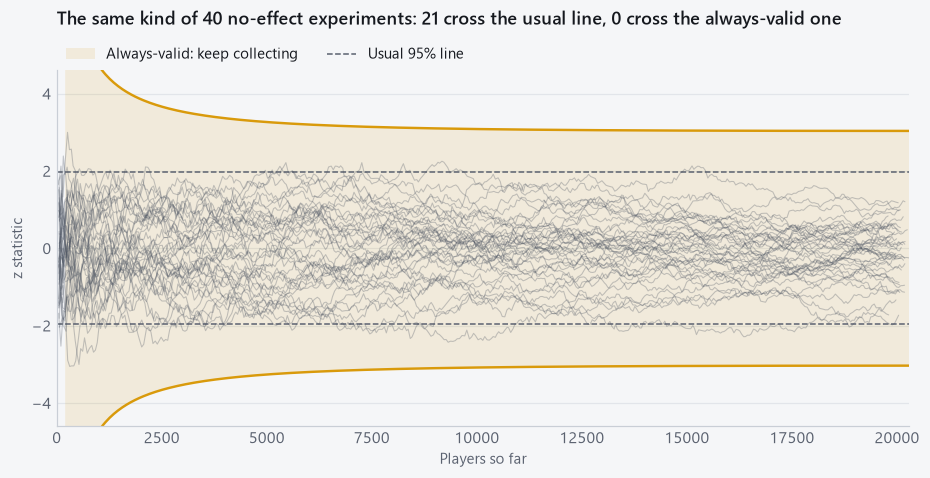

In [8]:
# The boundary: the usual line is flat at 1.96; the always-valid one is a curve in z units.
fig, ax = plt.subplots(figsize=(10, 4.2))
show_runs = 40
x, Z = null["n"][:show_runs], null["z"][:show_runs]
grid_n = np.linspace(200, x.max(), 400)
bound = cs_multiplier(grid_n, RHO2)
ax.fill_between(grid_n, -bound, bound, color=TREAT, alpha=0.12, lw=0, label="Always-valid: keep collecting")
ax.plot(grid_n, bound, color=TREAT, lw=1.6)
ax.plot(grid_n, -bound, color=TREAT, lw=1.6)
ax.axhline(1.96, color=MUTED, ls="--", lw=1, label="Usual 95% line")
ax.axhline(-1.96, color=MUTED, ls="--", lw=1)
for r in range(show_runs):
    ax.plot(x[r], Z[r], color=CONTROL, lw=0.7, alpha=0.3)
crossed = (np.abs(Z) > cs_multiplier(x, RHO2)) & (x >= MIN_N)
n_cs = int(crossed.any(1).sum())
n_nv = int(((np.abs(Z) > 1.96)).any(1).sum())
ax.set_ylim(-4.6, 4.6)
ax.set_xlim(0, x.max())
ax.set_xlabel("Players so far")
ax.set_ylabel("z statistic")
ax.set_title(f"The same kind of 40 no-effect experiments: {n_nv} cross the usual line, {n_cs} cross the always-valid one",
             pad=30)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncols=2, borderaxespad=0.2)
savefig(fig, "03_boundary_vs_paths")

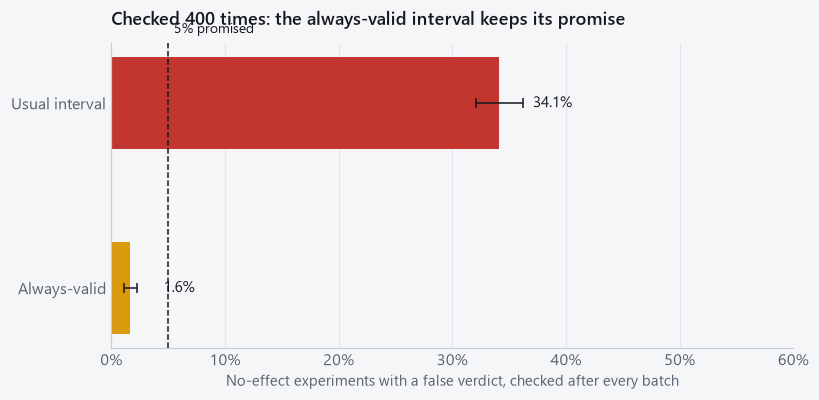

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.6))
labels = ["Usual interval", "Always-valid"]
vals = fa.xs("from 1,000 players", level=1).reindex(labels)
ax.barh(labels[::-1], vals.rate[::-1], color=[TREAT, STOP], height=0.5)
ax.errorbar(vals.rate[::-1], labels[::-1], xerr=[vals.rate[::-1] - vals.ci_low[::-1], vals.ci_high[::-1] - vals.rate[::-1]],
            fmt="none", ecolor=INK, capsize=3, lw=1)
ax.axvline(ALPHA, color=INK, ls="--", lw=1)
ax.text(ALPHA + 0.005, 1.38, "5% promised", fontsize=9, color=INK)
for y, v in enumerate(vals.rate[::-1]):
    ax.text(v + 0.03, y, f"{v:.1%}", va="center", fontsize=10, color=INK)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlim(0, max(0.6, vals.ci_high.max() + 0.08))
ax.grid(axis="y", visible=False)
ax.grid(axis="x")
ax.set_xlabel("No-effect experiments with a false verdict, checked after every batch")
ax.set_title("Checked 400 times: the always-valid interval keeps its promise")
savefig(fig, "03_false_alarms")

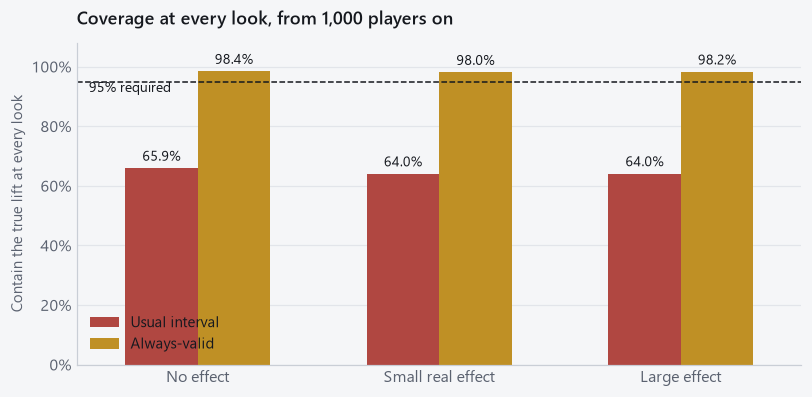

In [10]:
fig, ax = plt.subplots(figsize=(8.5, 3.8))
plot = cov.reset_index().rename(columns={"level_0": "preset", "level_1": "method"})
sns.barplot(plot, x="preset", y="rate", hue="method", palette={"Usual interval": STOP, "Always-valid": TREAT},
            ax=ax, width=0.6)
for bars in ax.containers:
    ax.bar_label(bars, labels=[f"{b.get_height():.1%}" for b in bars], fontsize=9, padding=3)
ax.axhline(0.95, color=INK, ls="--", lw=1)
ax.text(-0.45, 0.915, "95% required", ha="left", fontsize=9, color=INK)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_ylim(0, 1.08)
ax.set(xlabel="", ylabel="Contain the true lift at every look")
ax.legend(title=None, loc="lower left")
ax.set_title("Coverage at every look, from 1,000 players on")
savefig(fig, "03_coverage_every_look")

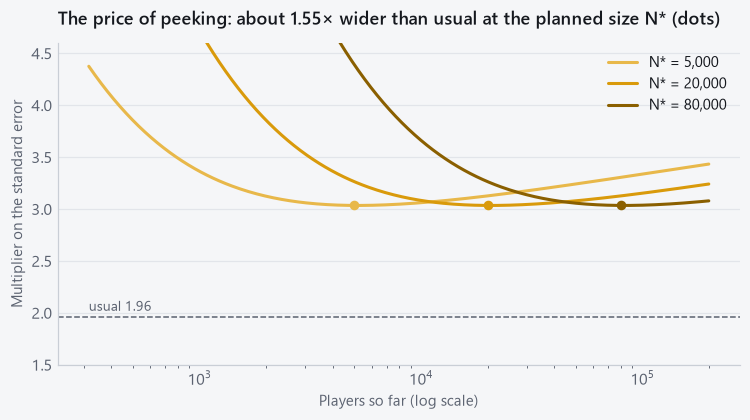

In [11]:
# The price of peeking: the multiplier that replaces 1.96, for different planned sample sizes N*.
fig, ax = plt.subplots(figsize=(8, 3.8))
ns = np.logspace(2.5, 5.3, 300)
for n_star, color in [(5_000, "#e8b84a"), (20_000, TREAT), (80_000, "#8a5f00")]:
    ax.plot(ns, cs_multiplier(ns, rho2_for(n_star)), color=color, lw=2, label=f"N* = {n_star:,}")
    ax.scatter([n_star], [cs_multiplier(n_star, rho2_for(n_star))], color=color, s=28, zorder=3)
ax.axhline(1.96, color=MUTED, ls="--", lw=1)
ax.text(ns[0], 2.02, "usual 1.96", fontsize=9, color=MUTED)
ax.set_xscale("log")
ax.set_xlabel("Players so far (log scale)")
ax.set_ylabel("Multiplier on the standard error")
ax.set_ylim(1.5, 4.6)
ax.set_title("The price of peeking: about 1.55× wider than usual at the planned size N* (dots)")
ax.legend(loc="upper right")
savefig(fig, "03_price_of_peeking")

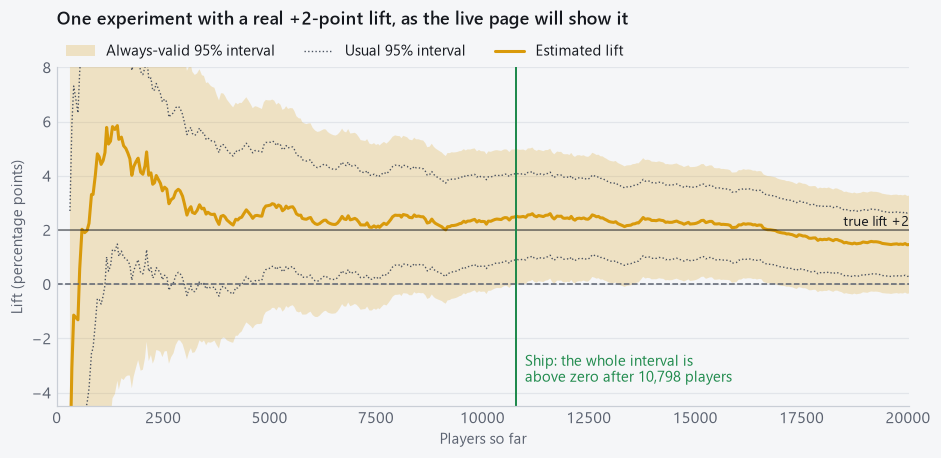

In [12]:
# One experiment under the Small real effect preset, the way the page will draw it.
res = runs["Small real effect"]
shipped, n_at = first_ship(res)
r = int(np.argmax(shipped & (n_at > 6_000) & (n_at < 16_000)))
xs = res["n"][r]
k_ship = int(np.argmax((res["cs_lo"][r] > 0) & (xs >= MIN_N)))
fig, ax = plt.subplots(figsize=(10, 4))
m = xs >= 300
ax.fill_between(xs[m], res["cs_lo"][r][m] * 100, res["cs_hi"][r][m] * 100, color=TREAT, alpha=0.22, lw=0,
                label="Always-valid 95% interval")
ax.plot(xs[m], res["nv_lo"][r][m] * 100, color=CONTROL, lw=0.9, ls=":", label="Usual 95% interval")
ax.plot(xs[m], res["nv_hi"][r][m] * 100, color=CONTROL, lw=0.9, ls=":")
ax.plot(xs[m], res["d"][r][m] * 100, color=TREAT, lw=2, label="Estimated lift")
ax.axhline(0, color=MUTED, ls="--", lw=1)
ax.axhline(2, color=INK, lw=1, alpha=0.6)
ax.text(xs[-1], 2.15, "true lift +2", ha="right", fontsize=9, color=INK)
ax.axvline(xs[k_ship], color=SHIP, lw=1.3)
ax.text(xs[k_ship] + 200, -3.6, f"Ship: the whole interval is\nabove zero after {xs[k_ship]:,} players",
        fontsize=9.5, color=SHIP)
ax.set_ylim(-4.5, 8)
ax.set_xlim(0, xs[-1])
ax.set_xlabel("Players so far")
ax.set_ylabel("Lift (percentage points)")
ax.set_title("One experiment with a real +2-point lift, as the live page will show it", pad=28)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncols=3, borderaxespad=0.2)
savefig(fig, "03_one_run_small_effect")

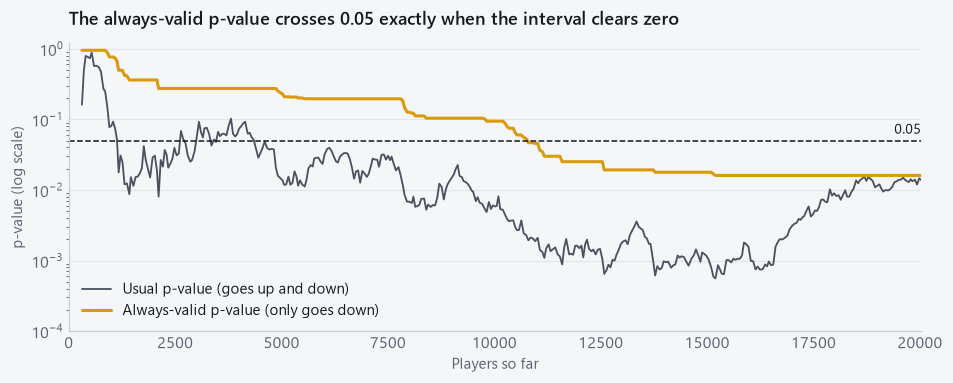

In [13]:
# Always-valid p-value vs the usual p-value, same experiment.
from scipy.stats import norm  # noqa: E402

fig, ax = plt.subplots(figsize=(10, 3.4))
p_naive = 2 * norm.sf(np.abs(res["z"][r]))
ax.plot(xs[m], p_naive[m], color=CONTROL, lw=1.2, label="Usual p-value (goes up and down)")
ax.plot(xs[m], res["p_av"][r][m], color=TREAT, lw=2, label="Always-valid p-value (only goes down)")
ax.axhline(ALPHA, color=INK, ls="--", lw=1)
ax.text(xs[-1], ALPHA * 1.25, "0.05", ha="right", fontsize=9, color=INK)
ax.set_yscale("log")
ax.set_ylim(1e-4, 1.2)
ax.set_xlim(0, xs[-1])
ax.set_xlabel("Players so far")
ax.set_ylabel("p-value (log scale)")
ax.legend(loc="lower left")
ax.set_title("The always-valid p-value crosses 0.05 exactly when the interval clears zero")
savefig(fig, "03_p_values")

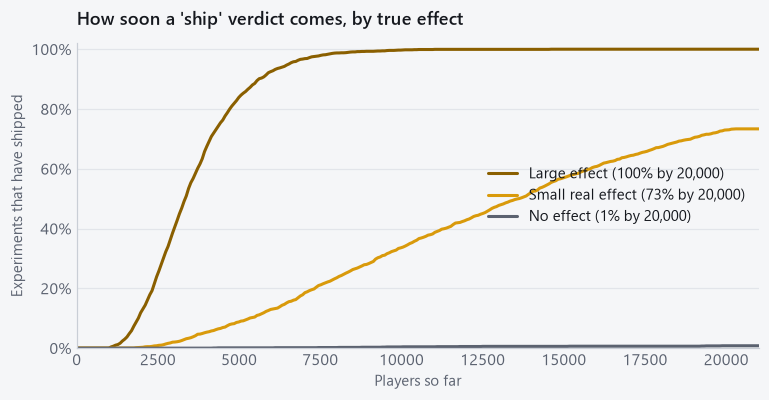

In [14]:
fig, ax = plt.subplots(figsize=(8, 3.6))
for preset, color in [("Large effect", "#8a5f00"), ("Small real effect", TREAT), ("No effect", MUTED)]:
    shipped, n_at = first_ship(runs[preset])
    grid_x = np.linspace(0, 21_000, 300)
    ecdf = [(n_at <= g).mean() for g in grid_x]  # NaN (never shipped) counts as not yet
    ax.plot(grid_x, ecdf, color=color, lw=2, label=f"{preset} ({shipped.mean():.0%} by 20,000)")
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_ylim(0, 1.02)
ax.set_xlim(0, 21_000)
ax.set_xlabel("Players so far")
ax.set_ylabel("Experiments that have shipped")
ax.set_title("How soon a 'ship' verdict comes, by true effect")
ax.legend(loc="center right")
savefig(fig, "03_time_to_ship")

### Keep the running intersection, so a verdict never flips back

In the experiment above the interval clears zero at the ship moment, but its lower edge drifts back below zero later on. Each interval in the sequence is valid at every look, so their **running intersection** is too:

$$
\big[\, \max_{m \le n} L_m,\; \min_{m \le n} U_m \,\big]
$$

"The truth is inside every interval" is the same event whether or not we intersect, so the 95% guarantee is unchanged. The intersected interval can only narrow, which is what the page should show: once it says "ship", it stays "ship".

In [15]:
def running_intersection(lo, hi):
    return np.maximum.accumulate(lo, axis=-1), np.minimum.accumulate(hi, axis=-1)


for preset, lift in PRESETS.items():
    lo, hi = running_intersection(runs[preset]["cs_lo"], runs[preset]["cs_hi"])
    runs[preset]["ri_lo"], runs[preset]["ri_hi"] = lo, hi

pd.DataFrame({
    preset: {"coverage, plain": covers_always(runs[preset], "cs", lift).mean(),
             "coverage, intersected": covers_always(runs[preset], "ri", lift).mean()}
    for preset, lift in PRESETS.items()
}).T

,"coverage, plain","coverage, intersected"
No effect,0.9840,0.9840
Small real effect,0.9805,0.9805
Large effect,0.9820,0.9820


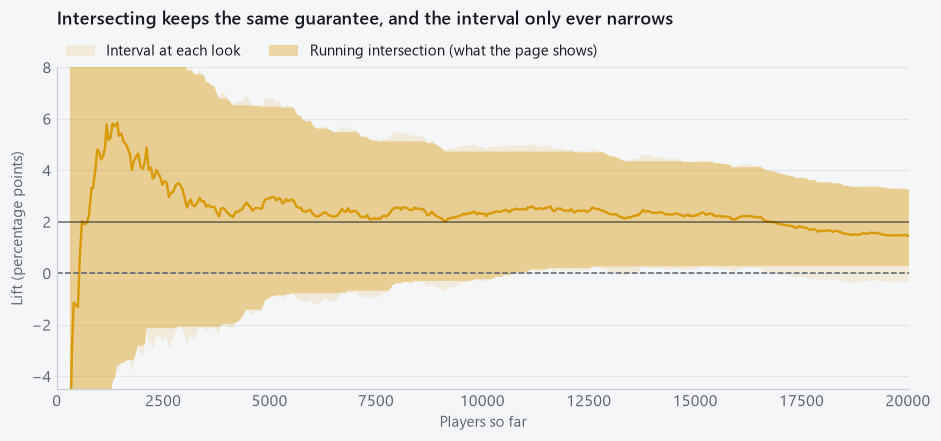

In [16]:
fig, ax = plt.subplots(figsize=(10, 3.8))
lo_i, hi_i = runs["Small real effect"]["ri_lo"][r], runs["Small real effect"]["ri_hi"][r]
ax.fill_between(xs[m], res["cs_lo"][r][m] * 100, res["cs_hi"][r][m] * 100, color=TREAT, alpha=0.12, lw=0,
                label="Interval at each look")
ax.fill_between(xs[m], lo_i[m] * 100, hi_i[m] * 100, color=TREAT, alpha=0.35, lw=0,
                label="Running intersection (what the page shows)")
ax.plot(xs[m], res["d"][r][m] * 100, color=TREAT, lw=1.6)
ax.axhline(0, color=MUTED, ls="--", lw=1)
ax.axhline(2, color=INK, lw=1, alpha=0.6)
ax.set_ylim(-4.5, 8)
ax.set_xlim(0, xs[-1])
ax.set_xlabel("Players so far")
ax.set_ylabel("Lift (percentage points)")
ax.set_title("Intersecting keeps the same guarantee, and the interval only ever narrows", pad=28)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncols=2, borderaxespad=0.2)
savefig(fig, "03_running_intersection")

## 6. Results

In [17]:
fa_cs = fa.loc[("Always-valid", "from 1,000 players")]
fa_cs0 = fa.loc[("Always-valid", "from the first look")]
fa_nv = fa.loc[("Usual interval", "from 1,000 players")]
print(f"Evidence 1  always-valid false alarms, from 1,000 players:  {fa_cs.rate:.2%}  "
      f"(95% CI {fa_cs.ci_low:.2%} to {fa_cs.ci_high:.2%})  -> {'PASS' if fa_cs.ci_low <= ALPHA else 'FAIL'}")
print(f"            ... counted from the very first look:            {fa_cs0.rate:.2%}")
print(f"Evidence 3  usual interval false alarms, same checking:      {fa_nv.rate:.2%}")
for preset in PRESETS:
    c = cov.loc[(preset, "Always-valid")]
    print(f"Evidence 2  coverage at every look, {preset:<18} {c.rate:.2%}  (95% CI {c.ci_low:.2%} to {c.ci_high:.2%})"
          f"  -> {'PASS' if c.ci_high >= 0.95 else 'FAIL'}")

Evidence 1  always-valid false alarms, from 1,000 players:  1.60%  (95% CI 1.14% to 2.25%)  -> PASS
            ... counted from the very first look:            1.60%
Evidence 3  usual interval false alarms, same checking:      34.10%
Evidence 2  coverage at every look, No effect          98.40%  (95% CI 97.75% to 98.86%)  -> PASS
Evidence 2  coverage at every look, Small real effect  98.05%  (95% CI 97.35% to 98.57%)  -> PASS
Evidence 2  coverage at every look, Large effect       98.20%  (95% CI 97.52% to 98.70%)  -> PASS


- **The method matches GrowthBook's engine** to machine precision on the interval and the per-look p-value.
- **Evidence 1 and 3.** Checked after every one of 400 batches, the always-valid interval raises far fewer false verdicts than the 5% allowed, while the usual interval raises them in roughly half the experiments (printed above). The always-valid method is conservative: it spends less than its 5% budget, because Ville's inequality is a bound, not an equality.
- **Evidence 2.** Under every preset, the always-valid interval contains the true lift at every look in at least 95% of experiments. The usual interval does not come close.
- **What it costs.** At the planned size the interval is about 1.55× wider than the usual one (multiplier 3.04 instead of 1.96). In exchange, real effects are still caught: the Large effect ships in almost every experiment and the Small effect in most, often well before 20,000 players.
- **The page shows the running intersection**, so a verdict never flips back; coverage is identical (table above).
- **Minimum sample.** Results are reported from 1,000 players on, following notebook 02. The row "from the first look" shows how much that matters; notebook 04 sets the actual minimum.

## 7. What gets promoted

| Function | Goes to | Guarded by |
|---|---|---|
| `rho2_for`, `cs_multiplier`, `log_wealth`, `always_valid_p`, `running_intersection` | `ablab/sequential.py` | `tests/test_sequential.py`: equals `gbstats.SequentialTwoSidedTTest` on fixtures; p-value never increases; p < α exactly when the interval excludes 0 |
| Validity simulation (evidence 1–3) | `validity/always_valid.py`, writes `results/always_valid.json` | The page cites this file; CI fails if a threshold is missed |
| Shared fixtures | `fixtures/sequential.json` | Same numbers checked by the TypeScript port in M2 (evidence 4) |

## 8. Production parity

The functions above now live in `ablab/sequential.py` (tested against `gbstats` in `tests/test_sequential.py`). The page draws the running intersection from the 1,000-player minimum, and `validity/always_valid.py` re-runs evidence 1–3 at the planned N* = 30,000 (`results/always_valid.json`).

In [18]:
from ablab import sequential as prod  # noqa: E402

assert prod.rho2_for(N_STAR) == RHO2
assert np.allclose(prod.cs_multiplier(null["n"], RHO2), cs_multiplier(null["n"], RHO2))
assert np.allclose(prod.always_valid_p(null["z"], null["n"], RHO2), null["p_av"])
print("ablab.sequential reproduces this notebook")

ablab.sequential reproduces this notebook


## Further reading

The confidence sequence on the page, its tuning, and how it is used in production. Where to find them: **[local]** = `docs/papers/` in this project (kept out of the repo) · **[Vega: folder]** = `Vega/paper-library/pdfs/<folder>/` (Vega's library also has text versions in `paper-library/md/` and notes in `paper-library/papers/`) · **[airline library: folder]** = `Projects/airline-experimentation/paper-library/pdfs/<folder>/` (a copy of Vega's library plus airline-related extras) · **[online]** = not in any library yet. ★ = read first.

Theory notes in this project: [anytime-valid](../docs/theory/anytime-valid.md), [sequential-chapter](../docs/theory/sequential-chapter.md).

- ★ Howard, S. R., Ramdas, A., McAuliffe, J., & Sekhon, J. (2021). Time-uniform, nonparametric, nonasymptotic confidence sequences. *Annals of Statistics* 49(2). The modern theory of confidence sequences, including tuning to a planned size. **[Vega: 04-sequential-anytime-valid]** (filed as 'Howard et al 2022')
- ★ Waudby-Smith, I., Arbour, D., Sinha, R., Kennedy, E. H., & Ramdas, A. (2023). Time-uniform central limit theory and asymptotic confidence sequences. arXiv:2103.06476. The exact interval used on the page (asymptotic, from running totals). **[online]** https://arxiv.org/abs/2103.06476
- ★ Maharaj, A. V., et al. (2023). Anytime-valid confidence sequences in an enterprise A/B testing platform. *WWW '23 Companion*. The same method in production at Adobe. **[local]** `2302.10108v1.pdf`
- Johari, R., et al. (2017). Peeking at A/B tests (*KDD 2017*). The mixture SPRT, the same family as this interval. **[Vega: 04-sequential-anytime-valid]**
- Robbins, H. (1970). Statistical methods related to the law of the iterated logarithm. *Annals of Mathematical Statistics* 41(5). Where the normal-mixture boundary comes from. **[online]** https://doi.org/10.1214/aoms/1177696786
- Ramdas, A., Grünwald, P., Vovk, V., & Shafer, G. (2023). Game-theoretic statistics and safe anytime-valid inference. *Statistical Science* 38(4). The big-picture view: betting, e-values, Ville's inequality. **[online]** https://doi.org/10.1214/23-STS894
- Spotify Engineering. *Choosing a Sequential Testing Framework: Comparisons and Discussions* (blog). Confidence sequences vs group-sequential tests vs mSPRT. **[Vega: 04-sequential-anytime-valid]**
- Spotify Engineering. *Bringing Sequential Testing to Experiments with Longitudinal Data, Part 2* (blog). **[Vega: 04-sequential-anytime-valid]**
- Ham, D. W., Bojinov, I., Lindon, M., & Tingley, M. (2022). Design-based confidence sequences: a general approach to risk mitigation in panel experiments. arXiv:2210.08639. Netflix's version, without model assumptions. **[online]** https://arxiv.org/abs/2210.08639
- Miller, E. *Simple Sequential A/B Testing* (blog). A simpler sequential rule, for contrast. **[Vega: 04-sequential-anytime-valid]**